# Лабораторная работа №1.2. Разведочный анализ данных (EDA) — регрессия

**Цель работы:** выполнить разведочный анализ двух наборов данных о качестве вина, объединить их и подготовить для задач регрессии (ЛР №2, 4, 6).

**Набор данных:** [Wine Quality (UCI)](https://archive.ics.uci.edu/dataset/186/wine+quality) — физико-химические показатели португальского вина *Vinho Verde*: `csv/winequality-red.csv` (1 599 образцов) и `csv/winequality-white.csv` (4 898 образцов).

### Целевой признак
**`quality`** — экспертная оценка качества (в данных от 3 до 9).

### Входные признаки
| Признак | Описание |
|---|---|
| `red` | тип вина: 1 — красное, 0 — белое (добавлен при объединении) |
| `fixed acidity` | фиксированная (винная) кислотность, г/дм³ |
| `volatile acidity` | летучая (уксусная) кислотность, г/дм³ |
| `citric acid` | лимонная кислота, г/дм³ |
| `residual sugar` | остаточный сахар, г/дм³ |
| `chlorides` | хлориды, г/дм³ |
| `free sulfur dioxide` / `total sulfur dioxide` | свободный / общий SO₂, мг/дм³ |
| `density` | плотность, г/см³ |
| `pH` | кислотность среды |
| `sulphates` | сульфаты калия, г/дм³ |
| `alcohol` | крепость, % об. |

## 1. Загрузка и объединение данных

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

white = pd.read_csv('csv/winequality-white.csv', sep=';').assign(red=0)
red = pd.read_csv('csv/winequality-red.csv', sep=';').assign(red=1)
print(f'Белое вино: {white.shape}, красное вино: {red.shape}')

data = pd.concat([red, white], axis=0, ignore_index=True)
data = data[['red'] + [c for c in data.columns if c != 'red']]
data.head()

Белое вино: (4898, 13), красное вино: (1599, 13)


,red,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,1,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,1,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Проверка пропусков и дубликатов

In [2]:
print('Пропусков всего:', int(data.isnull().sum().sum()))
print('Полных дубликатов:', int(data.duplicated().sum()))
data.describe().T

Пропусков всего: 0
Полных дубликатов: 1177


,count,mean,std,min,25%,50%,75%,max
red,6497.0,0.246114,0.430779,0.00000,0.00000,0.00000,0.00000,1.00000
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000


Пропусков нет. Полных дубликатов — 1 177 строк (≈18.1 % выборки): в исходном датасете UCI одинаковые физико-химические измерения соответствуют разным партиям стандартного вина, оценённым дегустаторами независимо, поэтому они сохранены в итоговом файле. При этом важно учитывать, что при обычном случайном разбиении (`train_test_split`) идентичные строки могут попасть и в обучающую, и в тестовую выборку, поэтому для строгой оценки без дублирования профилей в промышленных задачах рекомендуется предварительно удалять дубликаты (`drop_duplicates()`) или использовать групповую кросс-валидацию (`GroupKFold`).

## 3. Корреляционный анализ

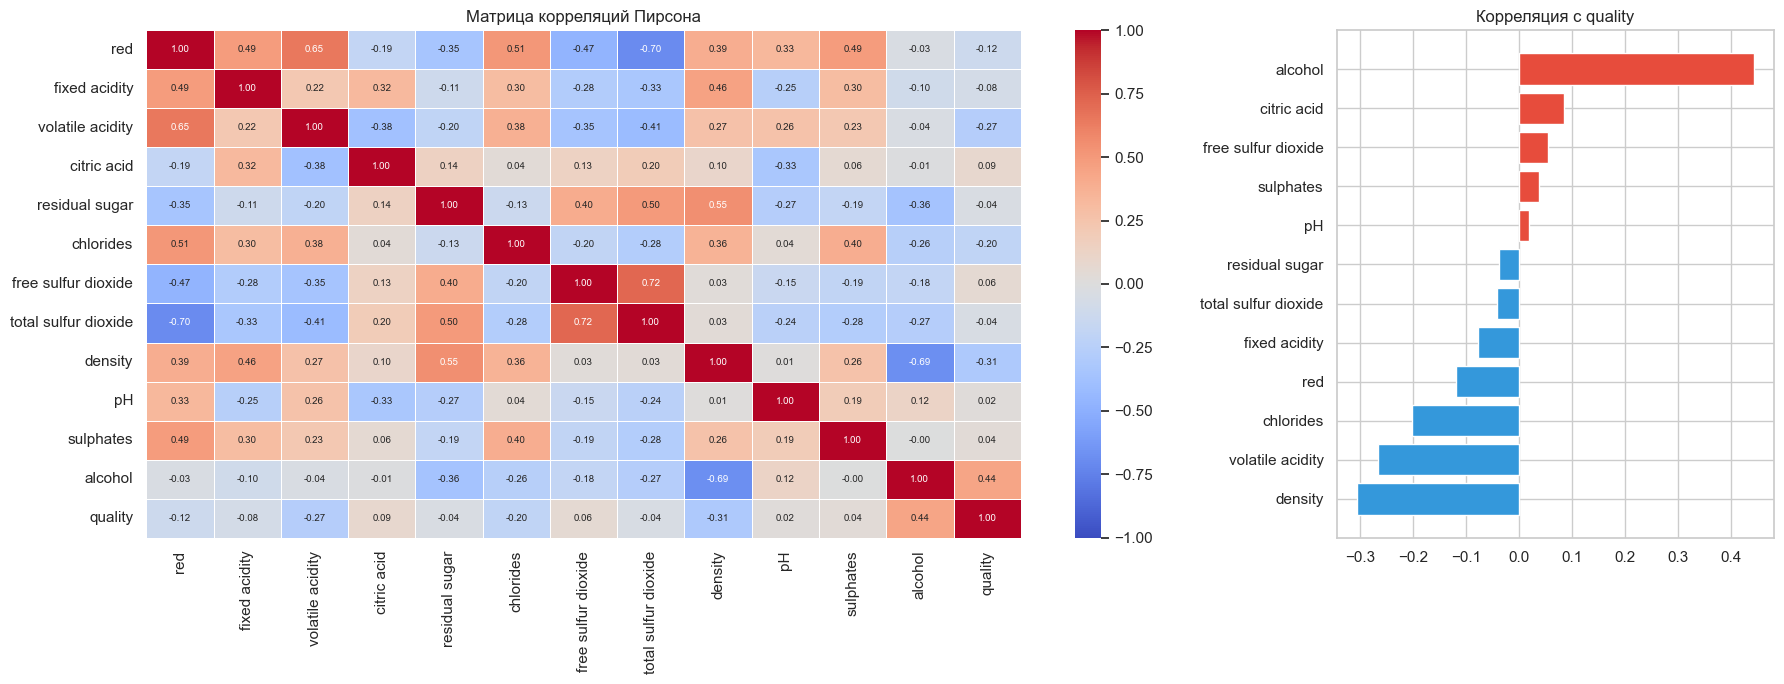

In [3]:
corr = data.corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [3, 1.2]})
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, linewidths=0.5, ax=axes[0])
axes[0].set_title('Матрица корреляций Пирсона')

q_corr = corr['quality'].drop('quality').sort_values()
axes[1].barh(q_corr.index, q_corr.values,
             color=['#e74c3c' if v > 0 else '#3498db' for v in q_corr])
axes[1].set_title('Корреляция с quality')
plt.tight_layout()
plt.show()

## 4. Распределение целевого признака

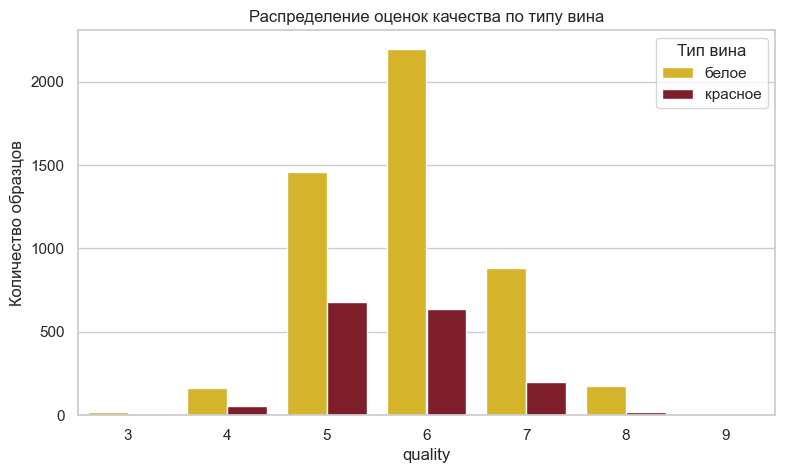

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=data, x='quality', hue='red', palette=['#f1c40f', '#8e0e1f'])
ax.legend(title='Тип вина', labels=['белое', 'красное'])
plt.title('Распределение оценок качества по типу вина')
plt.xlabel('quality')
plt.ylabel('Количество образцов')
plt.show()

print(data['quality'].value_counts(normalize=True).sort_index().round(3))

## 5. Распределения ключевых физико-химических признаков

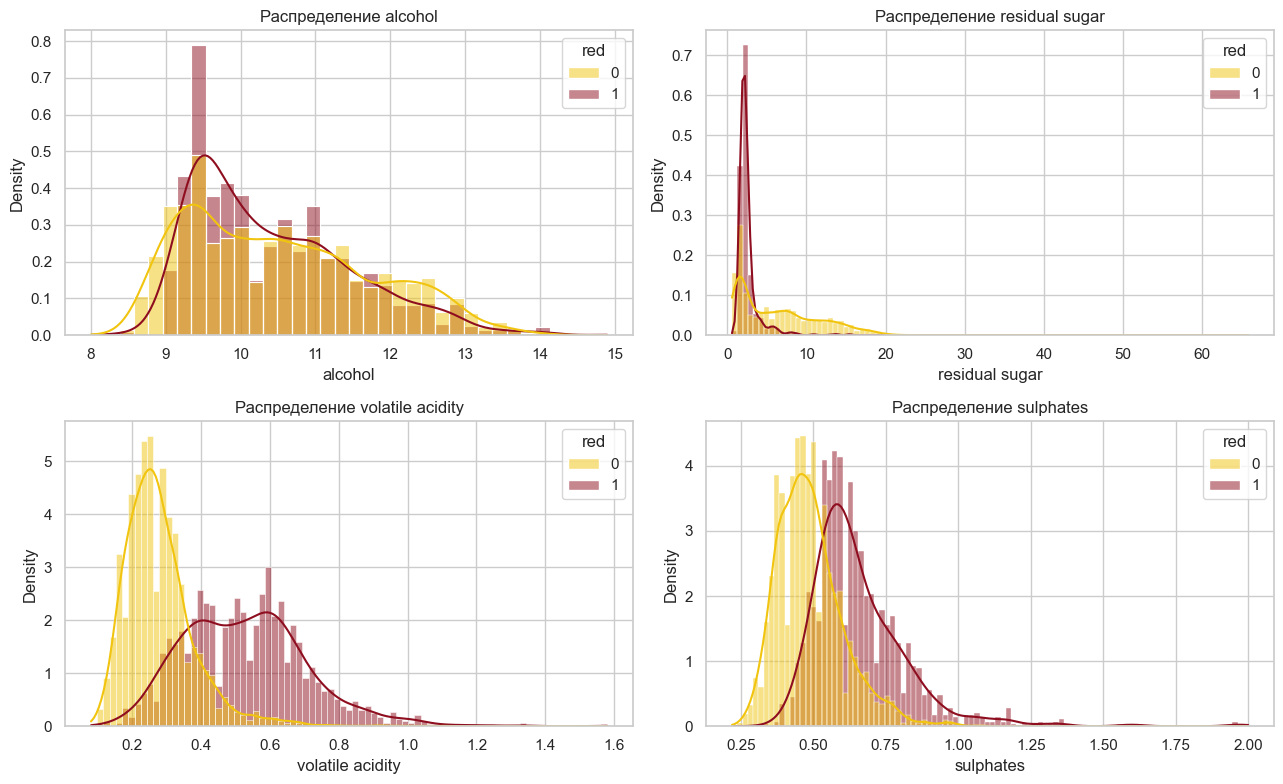

In [5]:
features = ['alcohol', 'residual sugar', 'volatile acidity', 'sulphates']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, feat in zip(axes.ravel(), features):
    sns.histplot(data=data, x=feat, hue='red', kde=True, stat='density',
                 common_norm=False, palette=['#f1c40f', '#8e0e1f'], ax=ax)
    ax.set_title(f'Распределение {feat}')
plt.tight_layout()
plt.show()

## 6. Зависимость качества от признаков

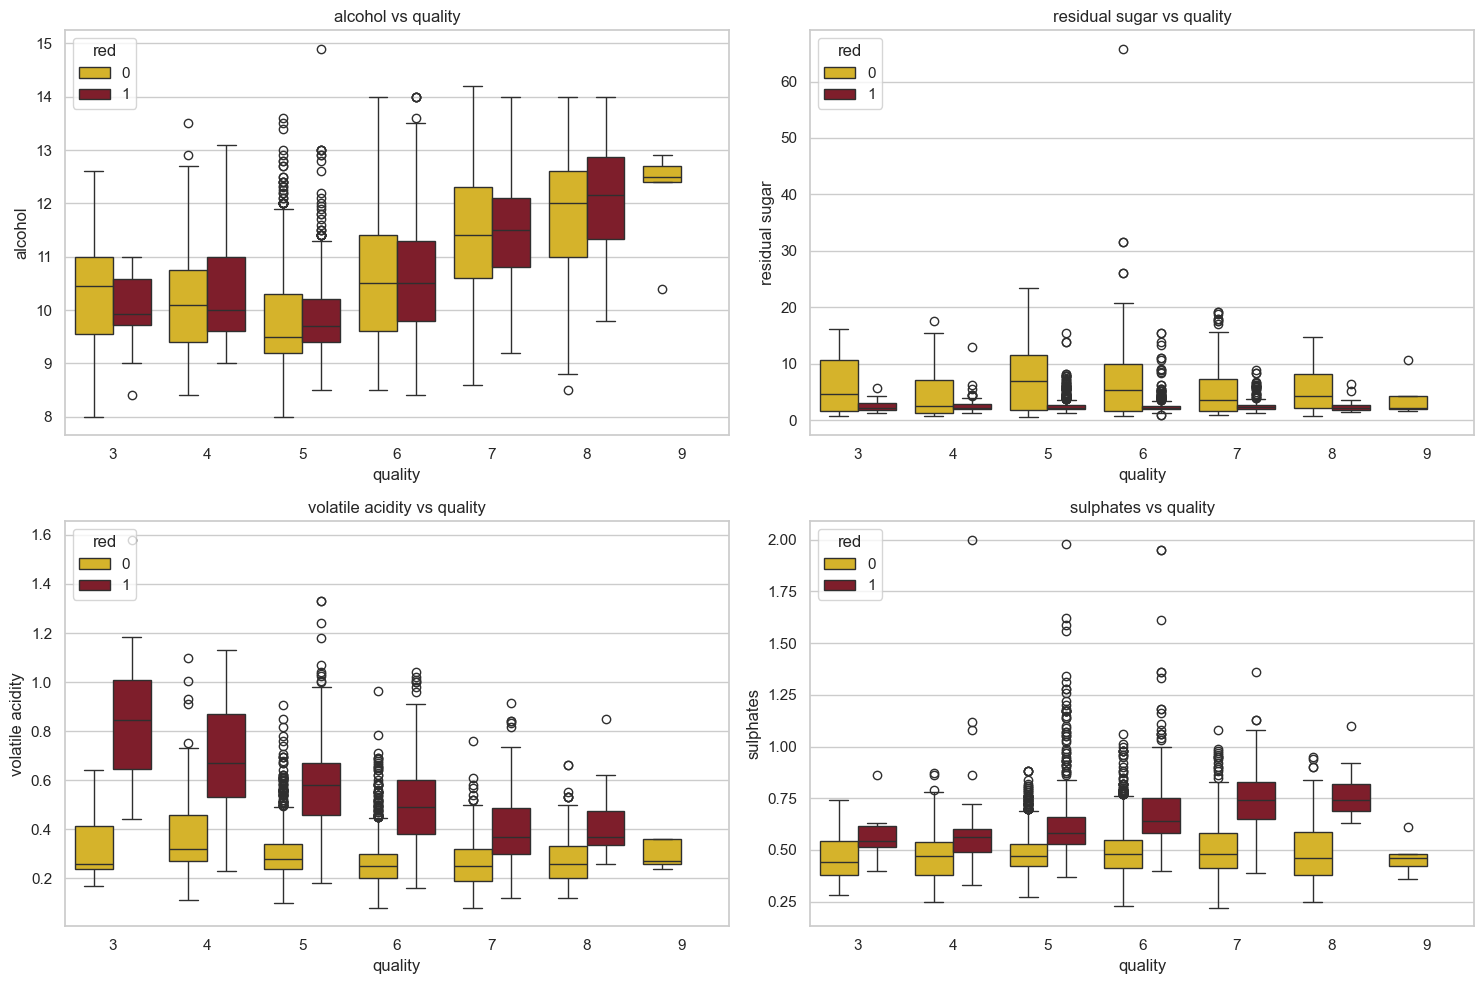

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=data, x='quality', y=feat, hue='red',
                palette=['#f1c40f', '#8e0e1f'], ax=ax)
    ax.set_title(f'{feat} vs quality')
    ax.legend(title='red', loc='upper left')
plt.tight_layout()
plt.show()

## 7. Сохранение объединённого набора данных

In [7]:
data.to_csv('csv/winequality_finished.csv', index=False, sep=';')
print(f'Сохранено в csv/winequality_finished.csv, размерность: {data.shape}')

Сохранено в csv/winequality_finished.csv, размерность: (6497, 13)


## Выводы
1. Объединены выборки красного (1 599) и белого (4 898) вина — итого **6 497 образцов**, 12 входных признаков (включая бинарный индикатор `red`). Пропусков нет; обнаружено 1 177 полных дубликатов (18.1 %), которые соответствуют повторным измерениям типовых партий вина (однако при строгой валидации моделей следует учитывать риск попадания идентичных физико-химических профилей одновременно в `train` и `test`).
2. **Целевая переменная `quality`** сильно сконцентрирована вокруг средних значений: оценки 5 (2 138 образцов) и 6 (2 836 образцов) составляют **76.6 %** всей выборки, тогда как экстремальные оценки 3 (30 образцов) и 9 (5 образцов) встречаются единично. Из-за этого модели регрессии неизбежно будут смещать прогнозы к центру распределения (5–6 баллов).
3. **Главный линейный фактор качества — крепость `alcohol`** ($r = 0.444$): медиана содержания спирта монотонно растёт с увеличением оценки качества для обоих типов вина. Отрицательную корреляцию с качеством демонстрируют плотность `density` ($r = -0.306$), летучая кислотность `volatile acidity` ($r = -0.266$) и хлориды `chlorides` ($r = -0.201$).
4. Красное и белое вино существенно различаются по химическому профилю: в белом вине значительно выше уровень `total sulfur dioxide` ($r = -0.700$ с признаком `red`) и `residual sugar` ($r = -0.349$), а в красном — выше `volatile acidity` ($r = 0.653$), `chlorides` ($r = 0.512$) и `sulphates` ($r = 0.487$). Поэтому бинарный признак `red` несёт важную разделяющую информацию.
5. Выявлена сильная мультиколлинеарность между физико-химическими признаками (`density` ↔ `alcohol` $r = -0.687$, `density` ↔ `residual sugar` $r = 0.553$, `free sulfur dioxide` ↔ `total sulfur dioxide` $r = 0.721$), что обосновывает необходимость применения $L_1$/$L_2$-регуляризации в линейных моделях (ЛР №2) и методов снижения размерности (ЛР №6).